In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
print("ready")


ready


In [ ]:
%cd /
import pandas as pd

umd = pd.read_csv('cyber_events_2026-11-10.csv', low_memory=False)
ic3 = pd.read_csv('ic3_complaints_by_state.csv')
pop = pd.read_csv('ACSDT1Y2025.B01003-2026-11-10T204727.csv')
net = pd.read_csv('ACSST1Y2025.S2801-2026-11-10T204620.csv')

print(umd.shape, ic3.shape, pop.shape, net.shape)
print(umd[['year','country','state','county']].head())

/
(17753, 44) (56, 3) (1, 105) (34, 209)
   year                                            country state county
0  2026                                             Serbia   NaN    NaN
1  2026  United Kingdom of Great Britain and Northern I...   NaN    NaN
2  2026                                             Russia   NaN    NaN
3  2026                                              India   NaN    NaN
4  2026                                              Japan   NaN    NaN


In [ ]:
# Census থেকে স্টেটভিত্তিক জনসংখ্যা বের করা
est = pop.iloc[0, 1:]
est = est[[c for c in est.index if c.endswith('!!Estimate')]]
pop_df = pd.DataFrame({
    'state': [c.replace('!!Estimate', '') for c in est.index],
    'population': est.astype(str).str.replace(',', '').astype(int).values
})

# IC3 এর সঙ্গে জোড়া লাগানো ও হার হিসাব
t = ic3.merge(pop_df, on='state', how='inner')
t['per100k_2025'] = (t['complaints_2025'] / t['population'] * 100000).round(1)
t['per100k_2024'] = (t['complaints_2024'] / t['population'] * 100000).round(1)

print(len(t), "states matched")
print(t.sort_values('per100k_2025', ascending=False).head(8).to_string())
print(t.sort_values('per100k_2025').head(8).to_string())
print("2024 vs 2025 correlation:", t['per100k_2025'].corr(t['per100k_2024']))

52 states matched
                   state  complaints_2024  complaints_2025  population  per100k_2025  per100k_2024
8   District of Columbia             3856             3113      693645         448.8         555.9
1                 Alaska             6770             3202      737270         434.3         918.3
28                Nevada            10716            13366     3282188         407.2         326.5
2                Arizona            20101            28868     7623818         378.7         263.7
21         Massachusetts            14254            22936     7154084         320.6         199.2
48            Washington            18009            25619     8001020         320.2         225.1
5               Colorado            14848            18847     6012561         313.5         246.9
20              Maryland            14996            19430     6265347         310.1         239.3
           state  complaints_2024  complaints_2025  population  per100k_2025  per100k_2024


52 states
Pearson : 0.626
Spearman: 0.676


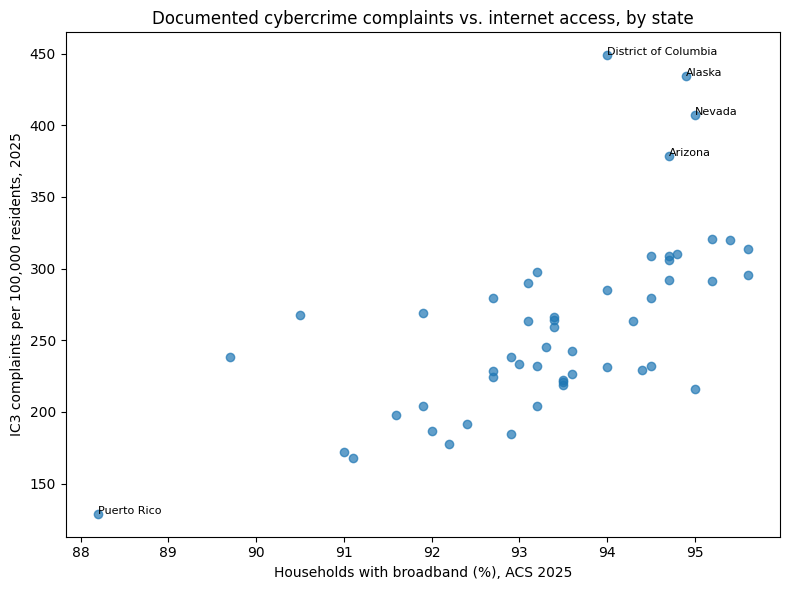

In [ ]:
import matplotlib.pyplot as plt

# S2801 থেকে ব্রডব্যান্ড-ব্যবহারকারী পরিবারের শতাংশ
net['label'] = net.iloc[:, 0].str.replace('\xa0', '', regex=False).str.strip()
row = net[net['label'] == 'Broadband of any type'].iloc[0]
cols = [c for c in net.columns if c.endswith('Percent!!Estimate')]
bb = pd.DataFrame({
    'state': [c.split('!!')[0] for c in cols],
    'broadband_pct': [float(str(row[c]).replace('%', '')) for c in cols]
})
t2 = t.merge(bb, on='state')

print(len(t2), "states")
print("Pearson :", round(t2['per100k_2025'].corr(t2['broadband_pct']), 3))
print("Spearman:", round(t2['per100k_2025'].corr(t2['broadband_pct'], method='spearman'), 3))

# স্ক্যাটার প্লট
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(t2['broadband_pct'], t2['per100k_2025'], alpha=0.7)
for _, r in t2.iterrows():
    if r['per100k_2025'] > 330 or r['per100k_2025'] < 150:
        ax.annotate(r['state'], (r['broadband_pct'], r['per100k_2025']), fontsize=8)
ax.set_xlabel('Households with broadband (%), ACS 2025')
ax.set_ylabel('IC3 complaints per 100,000 residents, 2025')
ax.set_title('Documented cybercrime complaints vs. internet access, by state')
plt.tight_layout()
plt.savefig('fig1_broadband_vs_complaints.png', dpi=200)
plt.show()

In [ ]:
# 1) UMD-র আমেরিকার ঘটনা এবং অনির্ধারিত লোকেশন
us = umd[umd['country'] == 'United States of America'].copy()
st_known  = us['state'].notna()  & (us['state']  != 'Undetermined')
cty_known = us['county'].notna() & (us['county'] != 'Undetermined')
print("US events:", len(us))
print("State unknown :", (~st_known).sum(),  f"({(~st_known).mean()*100:.1f}%)")
print("County unknown:", (~cty_known).sum(), f"({(~cty_known).mean()*100:.1f}%)")

# 2) 2023-2025 সালের স্টেটভিত্তিক ঘটনা (লোকেশন জানা আছে এমন)
rec = us[us['year'].between(2023, 2025) & st_known]
cnt = rec['state'].value_counts().rename('umd_events').rename_axis('state').reset_index()

m = pop_df.merge(ic3, on='state').merge(cnt, on='state', how='left').fillna({'umd_events': 0})
m['umd_per_million'] = m['umd_events'] / m['population'] * 1e6
m['ic3_per100k']     = m['complaints_2025'] / m['population'] * 1e5

print("\nSpearman (UMD count vs population):", round(m['umd_events'].corr(m['population'], method='spearman'), 3))
print("Spearman (IC3 count vs population):", round(m['complaints_2025'].corr(m['population'], method='spearman'), 3))
print("Spearman (UMD rate vs IC3 rate)   :", round(m['umd_per_million'].corr(m['ic3_per100k'], method='spearman'), 3))
print(m.sort_values('umd_per_million', ascending=False).head(5)[['state','umd_events','umd_per_million','ic3_per100k']].to_string())

US events: 8349
State unknown : 1474 (17.7%)
County unknown: 1976 (23.7%)

Spearman (UMD count vs population): 0.957
Spearman (IC3 count vs population): 0.978
Spearman (UMD rate vs IC3 rate)   : 0.003
            state  umd_events  umd_per_million  ic3_per100k
19          Maine        19.0        13.428758   204.117116
21  Massachusetts        84.0        11.741545   320.600094
16         Kansas        31.0        10.412391   266.254918
34   North Dakota         8.0        10.008031   177.392357
15           Iowa        27.0         8.337484   167.861346


In [ ]:
import numpy as np
rng = np.random.default_rng(42)

obs = m['umd_per_million'].corr(m['ic3_per100k'], method='spearman')

# A) স্টেট-বুটস্ট্র্যাপ: ৫২টা স্টেট বারবার নমুনা নিয়ে অনিশ্চয়তার পরিসর
bs = []
for _ in range(5000):
    s = m.sample(len(m), replace=True, random_state=int(rng.integers(1e9)))
    bs.append(s['umd_per_million'].corr(s['ic3_per100k'], method='spearman'))
print("observed:", round(obs, 3), "| bootstrap 95% CI:", np.round(np.percentile(bs, [2.5, 97.5]), 3))

# B) সিমুলেশন: UMD যদি ঠিক IC3-র ভৌগোলিক বণ্টন মানত,
#    তবুও ছোট সংখ্যার কারণে কত সম্পর্ক দেখা যেত?
tot = m['umd_events'].sum()
share = m['complaints_2025'] / m['complaints_2025'].sum()
sims = []
for _ in range(5000):
    sim = rng.poisson(share * tot)
    sims.append(pd.Series(sim / m['population'] * 1e6).corr(m['ic3_per100k'], method='spearman'))
print("simulated if UMD followed IC3:", round(np.mean(sims), 3), "| 95% range:", np.round(np.percentile(sims, [2.5, 97.5]), 3))

observed: 0.003 | bootstrap 95% CI: [-0.294  0.304]
simulated if UMD followed IC3: 0.693 | 95% range: [0.529 0.818]


In [ ]:
!pip install -q -U google-genai

from google import genai
from google.colab import userdata

client = genai.Client(api_key=userdata.get('GEMINI_API_KEY'))

# কোন মডেলগুলো তোমার key-তে চলে তার তালিকা
for mdl in client.models.list():
    print(mdl.name)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.2 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.1.0 which is incompatible.
models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3.1-flash-lite
models/gemini-3-pro-image
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-4-argon
models/gemini-4-carbon
models/antigravity-preview-05-2026
models/antigravity-preview-09-2026
models/antigravity-preview-latest
model

In [ ]:
import time, json
from google.genai import types

MODEL = "gemini-2.5-flash"
PROMPT = ("Approximately how many cybercrime complaints did residents of {state} file with the "
          "FBI Internet Crime Complaint Center (IC3) in 2024? If you do not know, you may answer null. "
          'Respond ONLY as JSON: {{"estimate": <integer or null>, "confidence": <number 0 to 1>, '
          '"note": "<one short sentence>"}}')
cfg = types.GenerateContentConfig(response_mime_type="application/json", temperature=0.7)

def ask(state, tries=4):
    for k in range(tries):
        try:
            r = client.models.generate_content(model=MODEL, contents=PROMPT.format(state=state), config=cfg)
            return json.loads(r.text)
        except Exception as e:
            print("  retry", state, type(e).__name__, str(e)[:80])
            time.sleep(15 * (k + 1))
    return {"estimate": None, "confidence": None, "note": "FAILED"}

states = list(t['state'])[:2]
rows = []
for s in states:
    out = ask(s); out.update(state=s, rep=0); rows.append(out); print(out)
    time.sleep(7)


  retry Alabama ClientError 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-
  retry Alabama ClientError 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-
  retry Alabama ClientError 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-
  retry Alabama ClientError 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-
{'estimate': None, 'confidence': None, 'note': 'FAILED', 'state': 'Alabama', 'rep': 0}
  retry Alaska ClientError 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-
  retry Alaska ClientError 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-
  retry Alaska ClientError 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-
  retry Alaska ClientError 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-
{'estimate': None, 'confidence': None, 'note'

In [ ]:
candidates = ["gemini-3.5-flash", "gemini-3.1-flash-lite", "gemini-2.5-flash-lite",
              "gemini-3.6-flash", "gemini-2.5-flash"]

working = []
for name in candidates:
    try:
        r = client.models.generate_content(model=name, contents="Reply with the single word: OK")
        print("WORKS  :", name, "->", r.text.strip()[:20])
        working.append(name)
    except Exception as e:
        print("FAILS  :", name, "->", str(e)[:250])
    time.sleep(5)

print("\nWorking models:", working)

FAILS  : gemini-3.5-flash -> name 'client' is not defined


NameError: name 'time' is not defined

In [ ]:
!pip install -q -U google-genai

%cd /
import time, json
import pandas as pd, numpy as np
from google import genai
from google.colab import userdata

umd = pd.read_csv('cyber_events_2026-11-10.csv', low_memory=False)
ic3 = pd.read_csv('ic3_complaints_by_state.csv')
pop = pd.read_csv('ACSDT1Y2025.B01003-2026-11-10T204727.csv')
net = pd.read_csv('ACSST1Y2025.S2801-2026-11-10T204620.csv')

est = pop.iloc[0, 1:]
est = est[[c for c in est.index if c.endswith('!!Estimate')]]
pop_df = pd.DataFrame({
    'state': [c.replace('!!Estimate', '') for c in est.index],
    'population': est.astype(str).str.replace(',', '').astype(int).values
})
t = ic3.merge(pop_df, on='state', how='inner')
t['per100k_2025'] = (t['complaints_2025'] / t['population'] * 100000).round(1)
t['per100k_2024'] = (t['complaints_2024'] / t['population'] * 100000).round(1)

client = genai.Client(api_key=userdata.get('GEMINI_API_KEY'))
print("ready:", umd.shape, t.shape)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.2 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.1.0 which is incompatible.
/


FileNotFoundError: [Errno 2] No such file or directory: 'cyber_events_2026-11-10.csv'

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving ic3_complaints_by_state.csv to ic3_complaints_by_state.csv
Saving cyber_events_2026-11-10.csv to cyber_events_2026-11-10.csv
Saving ACSDT1Y2025.B01003-2026-11-10T204727.csv to ACSDT1Y2025.B01003-2026-11-10T204727.csv
Saving ACSST1Y2025.S2801-2026-11-10T204620.csv to ACSST1Y2025.S2801-2026-11-10T204620.csv


In [ ]:
import time, json
import pandas as pd, numpy as np
from google import genai
from google.colab import userdata

umd = pd.read_csv('cyber_events_2026-11-10.csv', low_memory=False)
ic3 = pd.read_csv('ic3_complaints_by_state.csv')
pop = pd.read_csv('ACSDT1Y2025.B01003-2026-11-10T204727.csv')
net = pd.read_csv('ACSST1Y2025.S2801-2026-11-10T204620.csv')

est = pop.iloc[0, 1:]
est = est[[c for c in est.index if c.endswith('!!Estimate')]]
pop_df = pd.DataFrame({
    'state': [c.replace('!!Estimate', '') for c in est.index],
    'population': est.astype(str).str.replace(',', '').astype(int).values
})
t = ic3.merge(pop_df, on='state', how='inner')
t['per100k_2025'] = (t['complaints_2025'] / t['population'] * 100000).round(1)
t['per100k_2024'] = (t['complaints_2024'] / t['population'] * 100000).round(1)

client = genai.Client(api_key=userdata.get('GEMINI_API_KEY'))
print("ready:", umd.shape, t.shape)

ready: (17753, 44) (52, 6)


In [ ]:
candidates = ["gemini-3.5-flash", "gemini-3.1-flash-lite", "gemini-2.5-flash-lite",
              "gemini-3.6-flash", "gemini-2.5-flash"]

working = []
for name in candidates:
    try:
        r = client.models.generate_content(model=name, contents="Reply with the single word: OK")
        print("WORKS  :", name, "->", r.text.strip()[:20])
        working.append(name)
    except Exception as e:
        print("FAILS  :", name, "->", str(e)[:250])
    time.sleep(5)

print("\nWorking models:", working)

WORKS  : gemini-3.5-flash -> OK
WORKS  : gemini-3.1-flash-lite -> OK
FAILS  : gemini-2.5-flash-lite -> 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-flash-lite is no longer available to new users. Please update your code to use models/gemini-3.5-flash-lite for the latest features and improvements. We recommend you to 
WORKS  : gemini-3.6-flash -> OK
FAILS  : gemini-2.5-flash -> 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-flash is no longer available to new users. Please update your code to use models/gemini-3.8-flash for the latest features and improvements. We recommend you to use the In

Working models: ['gemini-3.5-flash', 'gemini-3.1-flash-lite', 'gemini-3.6-flash']


In [ ]:
MODEL = "gemini-3.5-flash"
PROMPT = ("Approximately how many cybercrime complaints did residents of {state} file with the "
          "FBI Internet Crime Complaint Center (IC3) in 2024? If you do not know, you may answer null. "
          'Respond ONLY as JSON: {{"estimate": <integer or null>, "confidence": <number 0 to 1>, '
          '"note": "<one short sentence>"}}')

from google.genai import types
cfg = types.GenerateContentConfig(response_mime_type="application/json", temperature=0.7)

def ask(state, tries=4):
    for k in range(tries):
        try:
            r = client.models.generate_content(model=MODEL, contents=PROMPT.format(state=state), config=cfg)
            return json.loads(r.text)
        except Exception as e:
            print("  retry", state, type(e).__name__, str(e)[:150])
            time.sleep(15 * (k + 1))
    return {"estimate": None, "confidence": None, "note": "FAILED"}

for s in ["Iowa", "California"]:
    print(s, "->", ask(s))
    time.sleep(6)

Iowa -> {'estimate': 4000, 'confidence': 0.5, 'note': 'Estimated based on previous annual IC3 report trends for Iowa.'}
California -> {'estimate': None, 'confidence': 0.0, 'note': 'Official IC3 state-by-state complaint totals for 2024 are not available.'}


In [ ]:
import os, time, json
import pandas as pd

OUT = "probe_state_estimates.csv"
if os.path.exists(OUT):
    os.remove(OUT)              # আগের আংশিক ফল মুছছে (অন্য মডেলের ছিল)

MODEL = "gemini-3.1-flash-lite"
REPS = 1
PAUSE = 10

def ask(state, tries=3):
    for k in range(tries):
        try:
            r = client.models.generate_content(model=MODEL, contents=PROMPT.format(state=state), config=cfg)
            return json.loads(r.text)
        except Exception as e:
            print("  retry", state, str(e)[:60])
            time.sleep(30 * (k + 1))
    return None

rows, finished, fails = [], set(), 0
for s in t["state"]:
    for rep in range(REPS):
        if (s, rep) in finished:
            continue
        out = ask(s)
        if out is None:
            fails += 1
            if fails >= 3:
                break
            continue
        fails = 0
        out.update(state=s, rep=rep)
        rows.append(out)
        pd.DataFrame(rows).to_csv(OUT, index=False)
        time.sleep(PAUSE)
    if fails >= 3:
        print("STOPPED: 3 failures in a row (quota?). Saved so far:", len(rows))
        break
print("DONE" if fails < 3 else "PARTIAL", len(rows), "responses")

  retry Georgia 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This mo
  retry Kentucky 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This mo
  retry Michigan 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This mo
  retry Minnesota 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This mo
  retry Ohio 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This mo
  retry Rhode Island 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This mo
  retry South Carolina 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This mo
DONE 52 responses


In [ ]:
import matplotlib.pyplot as plt

pr = pd.read_csv("probe_state_estimates.csv")
pr['estimate'] = pd.to_numeric(pr['estimate'], errors='coerce')
pr['confidence'] = pd.to_numeric(pr['confidence'], errors='coerce')
d = t.merge(pr[['state','estimate','confidence','note']], on='state')
d['ratio'] = d['estimate'] / d['complaints_2024']
d['log_err'] = np.log(d['ratio'])
d['abs_log_err'] = d['log_err'].abs()
d['abstain'] = d['estimate'].isna()

print("States:", len(d), "| abstained (null):", int(d['abstain'].sum()))
print("Median ratio AI/actual:", round(float(np.exp(d['log_err'].median())), 2))
ok = d.dropna(subset=['estimate'])
sp = lambda a, b, x=ok: round(x[a].corr(x[b], method='spearman'), 3)
print("Spearman AI estimate vs actual       :", sp('estimate', 'complaints_2024'))
print("Spearman |log error| vs population   :", sp('abs_log_err', 'population'))
print("Spearman confidence vs |log error|   :", sp('confidence', 'abs_log_err'))
print("Mean population  abstained vs answered:",
      int(d[d['abstain']]['population'].mean()), "vs", int(ok['population'].mean()))
print("\nAbstained states:", sorted(d[d['abstain']]['state']))
print("\nMost off:")
print(ok.sort_values('abs_log_err', ascending=False).head(6)[['state','complaints_2024','estimate','confidence']].to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(ok['complaints_2024'], ok['estimate'], alpha=0.7)
lims = [ok['complaints_2024'].min()*0.5, ok['complaints_2024'].max()*2]
ax[0].plot(lims, lims, 'k--', lw=1)
ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('IC3 complaints 2024 (actual)'); ax[0].set_ylabel('Gemini estimate')
ax[0].set_title('AI estimate vs. actual by state')
ax[1].scatter(ok['population'], ok['abs_log_err'], alpha=0.7)
ax[1].set_xscale('log'); ax[1].set_xlabel('State population'); ax[1].set_ylabel('|log(estimate / actual)|')
ax[1].set_title('Estimation error vs. state size')
plt.tight_layout(); plt.savefig('fig2_ai_probe.png', dpi=200); plt.show()

States: 52 | abstained (null): 52
Median ratio AI/actual: nan
Spearman AI estimate vs actual       : nan
Spearman |log error| vs population   : nan
Spearman confidence vs |log error|   : nan


ValueError: cannot convert float NaN to integer

In [ ]:
raw = pd.read_csv("probe_state_estimates.csv")
print(raw.shape)
print(raw.dtypes)
print(raw.head(12).to_string())
print()
print(raw['note'].value_counts().head(5))

(52, 5)
estimate      float64
confidence      int64
note           object
state          object
rep             int64
dtype: object
    estimate  confidence                                                                note                 state  rep
0        NaN           0   The FBI IC3 2024 Internet Crime Report has not been released yet.               Alabama    0
1        NaN           0                 The FBI IC3 2024 report has not been published yet.                Alaska    0
2        NaN           0          The FBI IC3 2024 annual report has not yet been published.               Arizona    0
3        NaN           0                  The FBI IC3 2024 report has not been released yet.              Arkansas    0
4        NaN           0                 The FBI IC3 2024 report has not been published yet.            California    0
5        NaN           0                 The FBI IC3 2024 report has not yet been published.              Colorado    0
6        NaN           0    

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving ic3_complaints_by_state_v2.csv to ic3_complaints_by_state_v2 (1).csv


In [ ]:
import os, time, json
import pandas as pd

ic3 = pd.read_csv('ic3_complaints_by_state_v2.csv')
t = ic3.merge(pop_df, on='state', how='inner')
print("ready:", t.shape, t.columns.tolist())

OUT = "probe_2023_estimates.csv"
if os.path.exists(OUT):
    os.remove(OUT)

MODEL = "gemini-3.1-flash-lite"
REPS = 1
PAUSE = 10
PROMPT = ("Approximately how many cybercrime complaints did residents of {state} file with the "
          "FBI Internet Crime Complaint Center (IC3) in 2023? If you do not know, you may answer null. "
          'Respond ONLY as JSON: {{"estimate": <integer or null>, "confidence": <number 0 to 1>, '
          '"note": "<one short sentence>"}}')

# প্রথমে ২টা স্টেটে ছোট পরীক্ষা
def ask(state, tries=3):
    for k in range(tries):
        try:
            r = client.models.generate_content(model=MODEL, contents=PROMPT.format(state=state), config=cfg)
            return json.loads(r.text)
        except Exception as e:
            print("  retry", state, str(e)[:60])
            time.sleep(30 * (k + 1))
    return None

for s in ["Iowa", "California"]:
    print(s, "->", ask(s))
    time.sleep(6)

ready: (52, 5) ['state', 'complaints_2023', 'complaints_2024', 'complaints_2025', 'population']
Iowa -> {'estimate': 2728, 'confidence': 0.95, 'note': 'This figure is based on the 2023 FBI Internet Crime Report statistics for the state of Iowa.'}
California -> {'estimate': 80928, 'confidence': 0.95, 'note': 'The FBI IC3 2023 Internet Crime Report lists California as having 80,928 reported complaints.'}


In [ ]:
import os, time, json
import pandas as pd

OUT = "probe_2023_estimates.csv"
REPS = 3        # মোট ৩ রাউন্ড; চাইলে আগে থামিয়ে দিতে পারো

rows = pd.read_csv(OUT).to_dict("records") if os.path.exists(OUT) else []
finished = {(r["state"], r["rep"]) for r in rows}
fails = 0
stop = False
for rep in range(REPS):
    for s in t["state"]:
        if (s, rep) in finished:
            continue
        out = ask(s)
        if out is None:
            fails += 1
            if fails >= 3:
                stop = True
                break
            continue
        fails = 0
        out.update(state=s, rep=rep)
        rows.append(out)
        pd.DataFrame(rows).to_csv(OUT, index=False)
        time.sleep(PAUSE)
    if stop:
        print("STOPPED: 3 failures in a row. Saved so far:", len(rows))
        break
    print("round", rep, "finished | total saved:", len(rows))
print("DONE" if not stop else "PARTIAL", len(rows), "responses")

  retry California 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This mo
  retry California 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This mo
  retry California 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This mo
  retry Connecticut 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This mo
  retry District of Columbia 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This mo
  retry Florida 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This mo
  retry Maine 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This mo
  retry Mississippi 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This mo
  retry New Hampshire 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This mo
  retry New York 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This mo
  retry Virginia 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This mo
round 0 finished | total saved: 51
  retry Alaska 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This mo
  retr

Responses: 152 | states: 52 | null answers: 0
Median AI/actual ratio: 1.07
Share within +-20% of actual: 0.49
Mean stated confidence: 0.94
Confidence among WRONG answers (outside +-20%): 0.94

By state size (population quartile):
            states  median_abs_log_err  median_cv  mean_conf
size_group                                                  
smallest        13                0.30       0.05       0.95
small           13                0.23       0.05       0.95
large           13                0.22       0.08       0.94
largest         13                0.13       0.03       0.94

Spearman |log err| vs population: -0.256
Spearman spread (CV) vs population: -0.187


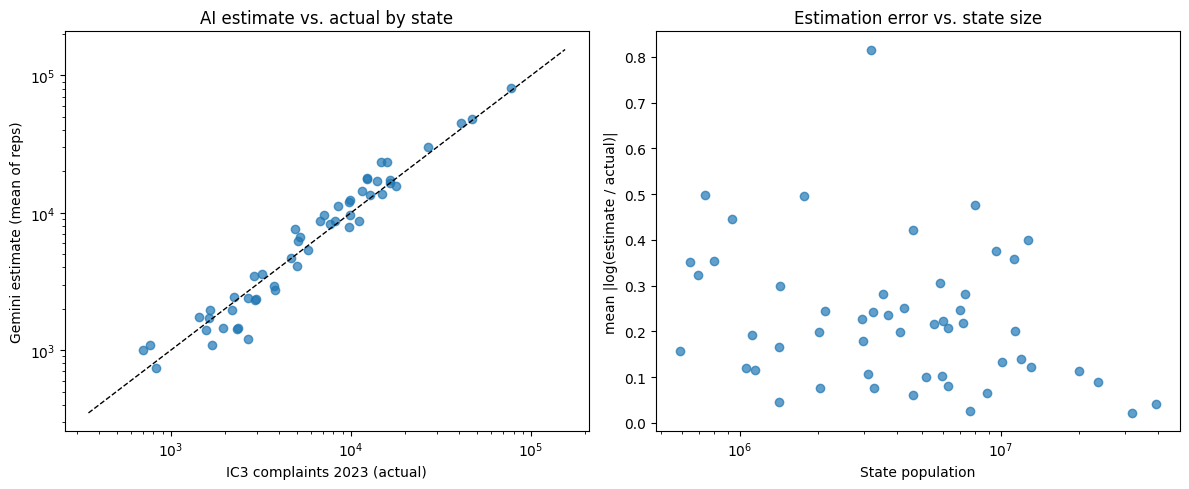

In [ ]:
import matplotlib.pyplot as plt

pr = pd.read_csv("probe_2023_estimates.csv")
pr['estimate'] = pd.to_numeric(pr['estimate'], errors='coerce')
pr['confidence'] = pd.to_numeric(pr['confidence'], errors='coerce')
r = pr.merge(t[['state','complaints_2023','population']], on='state')
r['log_err'] = np.log(r['estimate'] / r['complaints_2023'])
r['abs_log_err'] = r['log_err'].abs()
r['within20'] = (r['estimate'] / r['complaints_2023']).between(0.8, 1.2)

print("Responses:", len(r), "| states:", r['state'].nunique(), "| null answers:", int(r['estimate'].isna().sum()))
ok = r.dropna(subset=['estimate'])
print("Median AI/actual ratio:", round(float(np.exp(ok['log_err'].median())), 2))
print("Share within +-20% of actual:", round(ok['within20'].mean(), 2))
print("Mean stated confidence:", round(ok['confidence'].mean(), 2))
print("Confidence among WRONG answers (outside +-20%):", round(ok.loc[~ok['within20'], 'confidence'].mean(), 2))

g = ok.groupby('state').agg(est_mean=('estimate','mean'), est_sd=('estimate','std'),
                            abs_log_err=('abs_log_err','mean'), conf=('confidence','mean')).reset_index()
g = g.merge(t[['state','complaints_2023','population']], on='state')
g['cv'] = g['est_sd'] / g['est_mean']
g['size_group'] = pd.qcut(g['population'], 4, labels=['smallest','small','large','largest'])
print("\nBy state size (population quartile):")
print(g.groupby('size_group', observed=True).agg(states=('state','count'),
      median_abs_log_err=('abs_log_err','median'), median_cv=('cv','median'), mean_conf=('conf','mean')).round(2).to_string())
print("\nSpearman |log err| vs population:", round(g['abs_log_err'].corr(g['population'], method='spearman'), 3))
print("Spearman spread (CV) vs population:", round(g['cv'].corr(g['population'], method='spearman'), 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(g['complaints_2023'], g['est_mean'], alpha=0.7)
lims = [g['complaints_2023'].min()*0.5, g['complaints_2023'].max()*2]
ax[0].plot(lims, lims, 'k--', lw=1); ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('IC3 complaints 2023 (actual)'); ax[0].set_ylabel('Gemini estimate (mean of reps)')
ax[0].set_title('AI estimate vs. actual by state')
ax[1].scatter(g['population'], g['abs_log_err'], alpha=0.7)
ax[1].set_xscale('log'); ax[1].set_xlabel('State population'); ax[1].set_ylabel('mean |log(estimate / actual)|')
ax[1].set_title('Estimation error vs. state size')
plt.tight_layout(); plt.savefig('fig2_ai_probe_2023.png', dpi=200); plt.show()

In [ ]:
from scipy.stats import spearmanr
rho, p = spearmanr(g['population'], g['abs_log_err'])
print("Spearman rho =", round(rho, 3), "| p-value =", round(p, 3))

rng = np.random.default_rng(0)
small = g.nsmallest(13, 'population')['abs_log_err'].values
large = g.nlargest(13, 'population')['abs_log_err'].values
diffs = [np.median(rng.choice(small, 13)) - np.median(rng.choice(large, 13)) for _ in range(10000)]
print("Median error, smallest minus largest quartile:", round(np.median(small) - np.median(large), 3),
      "| 95% bootstrap CI:", np.round(np.percentile(diffs, [2.5, 97.5]), 3))

Spearman rho = -0.256 | p-value = 0.068
Median error, smallest minus largest quartile: 0.166 | 95% bootstrap CI: [-0.167  0.263]


In [ ]:
import os, time, json
import pandas as pd, numpy as np

us = umd[umd['country'] == 'United States of America']
k = us[us['county'].notna() & (us['county'] != 'Undetermined') & us['state'].notna() & (us['state'] != 'Undetermined')]
cnt = k.groupby(['state', 'county']).size().rename('umd_events').reset_index()

high = [("New York","New York"),("California","Los Angeles"),("Illinois","Cook"),("Texas","Harris"),
        ("Washington","King"),("Georgia","Fulton"),("Minnesota","Hennepin"),("Massachusetts","Middlesex")]
zero = [("Texas","Loving"),("Texas","Kenedy"),("Texas","King"),("Texas","Borden"),
        ("Nebraska","Arthur"),("Nebraska","McPherson"),("Montana","Petroleum"),("Montana","Treasure")]
low = cnt[cnt['umd_events'] == 1].sample(8, random_state=42)[['state','county']].values.tolist()

places = []
for grp, lst in [("S1_high", high), ("S2_one_event", low), ("S3_zero_events", zero)]:
    for s, c in lst:
        n = cnt[(cnt.state == s) & (cnt.county == c)]['umd_events']
        places.append(dict(stratum=grp, state=s, county=c, umd_events=int(n.iloc[0]) if len(n) else 0))
places = pd.DataFrame(places)
print(places.to_string())

P1 = ("Between 2014 and 2025, has any organization located in {county} County, {state} been publicly reported "
      "as the victim of a cyber attack (for example ransomware or a data breach)? Respond ONLY as JSON: "
      '{{"answer": "yes" or "no" or "unknown", "confidence": <number 0 to 1>, "note": "<one short sentence>"}}')
P2 = ("A national cybercrime database contains no recorded incidents for {county} County, {state}. "
      "Based only on this, can we conclude that no cybercrime has occurred there? Respond ONLY as JSON: "
      '{{"conclusion": "no_cybercrime_occurred" or "cannot_conclude", "confidence": <number 0 to 1>, "note": "<one short sentence>"}}')

def ask_prompt(prompt, tries=3):
    for k_ in range(tries):
        try:
            r = client.models.generate_content(model=MODEL, contents=prompt, config=cfg)
            return json.loads(r.text)
        except Exception as e:
            print("  retry", str(e)[:60])
            time.sleep(30 * (k_ + 1))
    return None

OUT = "probe_rq3.csv"
REPS = 2
rows = pd.read_csv(OUT).to_dict("records") if os.path.exists(OUT) else []
done = {(r["state"], r["county"], r["probe"], r["rep"]) for r in rows}
fails, stop = 0, False
for rep in range(REPS):
    for _, p in places.iterrows():
        for probe, tmpl in [("P1", P1), ("P2", P2)]:
            key = (p.state, p.county, probe, rep)
            if key in done:
                continue
            out = ask_prompt(tmpl.format(state=p.state, county=p.county))
            if out is None:
                fails += 1
                if fails >= 3:
                    stop = True
                    break
                continue
            fails = 0
            out.update(stratum=p.stratum, state=p.state, county=p.county, umd_events=p.umd_events, probe=probe, rep=rep)
            rows.append(out)
            pd.DataFrame(rows).to_csv(OUT, index=False)
            time.sleep(PAUSE)
        if stop:
            break
    if stop:
        print("STOPPED: 3 failures in a row. Saved so far:", len(rows))
        break
    print("round", rep, "finished | total saved:", len(rows))
print("DONE" if not stop else "PARTIAL", len(rows), "responses")

# ---- বিশ্লেষণ ----
r = pd.read_csv(OUT)
p1 = r[r.probe == "P1"]
print("\nP1 answers by stratum (share of responses):")
print(pd.crosstab(p1['stratum'], p1['answer'], normalize='index').round(2).to_string())
print("\nP1 mean confidence by stratum:")
print(p1.groupby('stratum')['confidence'].mean().round(2).to_string())
p2 = r[r.probe == "P2"]
print("\nP2 share saying 'cannot_conclude' (correct):", round((p2['conclusion'] == 'cannot_conclude').mean(), 2))

           stratum           state        county  umd_events
0          S1_high        New York      New York         236
1          S1_high      California   Los Angeles         205
2          S1_high        Illinois          Cook         162
3          S1_high           Texas        Harris         104
4          S1_high      Washington          King         113
5          S1_high         Georgia        Fulton         115
6          S1_high       Minnesota      Hennepin          70
7          S1_high   Massachusetts     Middlesex          72
8     S2_one_event  North Carolina        Gaston           1
9     S2_one_event    Rhode Island    Washington           1
10    S2_one_event         Alabama      Escambia           1
11    S2_one_event      New Jersey  Hillsborough           1
12    S2_one_event         Georgia     Gwinnett            1
13    S2_one_event        New York       Wyoming           1
14    S2_one_event         Wyoming    Sweetwater           1
15    S2_one_event   Wes

In [ ]:
p1 = r[r.probe == "P1"]
print(p1.groupby(['stratum','answer']).agg(responses=('answer','size'), mean_conf=('confidence','mean')).round(2).to_string())
print()
print(pd.crosstab([p1['stratum'], p1['county']], p1['answer']).to_string())
print()
print("Responses per stratum:", p1.groupby('stratum').size().to_dict())

                        responses  mean_conf
stratum        answer                       
S1_high        yes             16       1.00
S2_one_event   no               2       0.70
               unknown          1       0.50
               yes             13       0.92
S3_zero_events no               9       0.81
               unknown          6       0.76

answer                       no  unknown  yes
stratum        county                        
S1_high        Cook           0        0    2
               Fulton         0        0    2
               Harris         0        0    2
               Hennepin       0        0    2
               King           0        0    2
               Los Angeles    0        0    2
               Middlesex      0        0    2
               New York       0        0    2
S2_one_event   Escambia       0        0    2
               Gaston         0        0    2
               Gwinnett       0        0    2
               Hillsborough   0        0 

In [ ]:
import matplotlib.pyplot as plt

# ---- Figure 3: UMD-তে স্টেট-অজানা ঘটনার শতাংশ (বছর অনুযায়ী) ----
us = umd[umd['country'] == 'United States of America'].copy()
us['unknown_state'] = us['state'].isna() | (us['state'] == 'Undetermined')
g = us[us['year'].between(2014, 2025)].groupby('year')['unknown_state'].agg(['mean', 'size']).reset_index()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(g['year'], g['mean'] * 100, color='#2a78d6', width=0.6)
ax.set_xticks(g['year'])
ax.set_xticklabels([f"{y}\nn={n}" for y, n in zip(g['year'], g['size'])], fontsize=8)
for idx in [g['mean'].idxmax(), g['mean'].idxmin()]:
    ax.text(g.loc[idx, 'year'], g.loc[idx, 'mean'] * 100 + 0.8, f"{g.loc[idx, 'mean']*100:.0f}%", ha='center', fontsize=9)
ax.set_ylabel('% of U.S. events with unknown state')
ax.set_title('Documentation gaps in the UMD Cyber Events Database')
ax.spines[['top', 'right']].set_visible(False)
ax.yaxis.grid(True, color='#e5e5e5'); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig('fig3_umd_unknown_state.png', dpi=200); plt.show()

# ---- Figure 4: RQ3, P1 উত্তরের বণ্টন ----
r = pd.read_csv('probe_rq3.csv')
p1 = r[r['probe'] == 'P1']
order = ['S1_high', 'S2_one_event', 'S3_zero_events']
labels = ['High (70-236 events)', 'One event', 'No record']
cols = {'yes': '#2a78d6', 'no': '#eb6834', 'unknown': '#9aa0a6'}
ct = pd.crosstab(p1['stratum'], p1['answer']).reindex(order).reindex(columns=['yes', 'no', 'unknown']).fillna(0)

fig, ax = plt.subplots(figsize=(8, 3.6))
left = np.zeros(len(order))
for a in ['yes', 'no', 'unknown']:
    share = (ct[a] / ct.sum(axis=1)).values * 100
    ax.barh(labels, share, left=left, color=cols[a], edgecolor='white', linewidth=2, height=0.55, label=a)
    for i, (l, s_) in enumerate(zip(left, share)):
        if s_ > 6:
            ax.text(l + s_ / 2, i, f"{int(ct[a].iloc[i])}", ha='center', va='center', color='white', fontsize=10, fontweight='bold')
    left += share
ax.invert_yaxis()
ax.set_xlim(0, 100); ax.set_xlabel('% of P1 responses (numbers inside bars are response counts)')
ax.set_title('Has any organization in this county been reported as a cyber-attack victim?', fontsize=11)
ax.legend(ncol=3, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.25))
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('fig4_rq3_p1.png', dpi=200, bbox_inches='tight'); plt.show()

NameError: name 'umd' is not defined

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving probe_rq3 (1).csv to probe_rq3 (1).csv
Saving probe_2023_estimates (1).csv to probe_2023_estimates (1).csv
Saving ic3_complaints_by_state_v2.csv to ic3_complaints_by_state_v2.csv
Saving probe_state_estimates.csv to probe_state_estimates.csv
Saving ic3_complaints_by_state.csv to ic3_complaints_by_state.csv
Saving cyber_events_2026-11-10.csv to cyber_events_2026-11-10.csv
Saving ACSDT1Y2025.B01003-2026-11-10T204727.csv to ACSDT1Y2025.B01003-2026-11-10T204727.csv
Saving ACSST1Y2025.S2801-2026-11-10T204620.csv to ACSST1Y2025.S2801-2026-11-10T204620.csv


In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
umd = pd.read_csv('cyber_events_2026-11-10.csv', low_memory=False)

In [6]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

pop = pd.read_csv('ACSDT1Y2025.B01003-2026-11-10T204727.csv')
ic3 = pd.read_csv('ic3_complaints_by_state_v2.csv')
est = pop.iloc[0, 1:]
est = est[[c for c in est.index if c.endswith('!!Estimate')]]
pop_df = pd.DataFrame({'state': [c.replace('!!Estimate', '') for c in est.index],
                       'population': est.astype(str).str.replace(',', '').astype(int).values})
t = ic3.merge(pop_df, on='state')

pr = pd.read_csv('probe_2023_estimates.csv')
pr['estimate'] = pd.to_numeric(pr['estimate'], errors='coerce')
r = pr.merge(t[['state', 'complaints_2023', 'population']], on='state')
r['abs_log_err'] = np.log(r['estimate'] / r['complaints_2023']).abs()
g = r.dropna(subset=['estimate']).groupby('state').agg(est_mean=('estimate', 'mean'), abs_log_err=('abs_log_err', 'mean')).reset_index()
g = g.merge(t[['state', 'complaints_2023', 'population']], on='state')

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(g['complaints_2023'], g['est_mean'], alpha=0.7, color='#2a78d6')
lims = [g['complaints_2023'].min() * 0.5, g['complaints_2023'].max() * 2]
ax[0].plot(lims, lims, 'k--', lw=1); ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('IC3 complaints 2023 (actual)'); ax[0].set_ylabel('Gemini estimate (mean of repetitions)')
ax[0].set_title('AI estimate vs. actual by state')
ax[1].scatter(g['population'], g['abs_log_err'], alpha=0.7, color='#2a78d6')
ax[1].set_xscale('log'); ax[1].set_xlabel('State population'); ax[1].set_ylabel('mean |log(estimate / actual)|')
ax[1].set_title('Estimation error vs. state size')
for a in ax: a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('fig2_ai_probe_2023.png', dpi=200); plt.show()
print(len(r), "responses,", g['state'].nunique(), "states")

FileNotFoundError: [Errno 2] No such file or directory: 'probe_2023_estimates.csv'

In [8]:
import os
for old, new in [("probe_2023_estimates (1).csv", "probe_2023_estimates.csv"),
                 ("probe_rq3 (1).csv", "probe_rq3.csv")]:
    if os.path.exists(old):
        os.replace(old, new)
print(sorted(f for f in os.listdir('.') if f.endswith('.csv')))


['ACSDT1Y2025.B01003-2026-11-10T204727.csv', 'ACSST1Y2025.S2801-2026-11-10T204620.csv', 'cyber_events_2026-11-10.csv', 'ic3_complaints_by_state.csv', 'ic3_complaints_by_state_v2.csv', 'probe_2023_estimates.csv', 'probe_rq3.csv', 'probe_state_estimates.csv']


In [9]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
umd = pd.read_csv('cyber_events_2026-11-10.csv', low_memory=False)

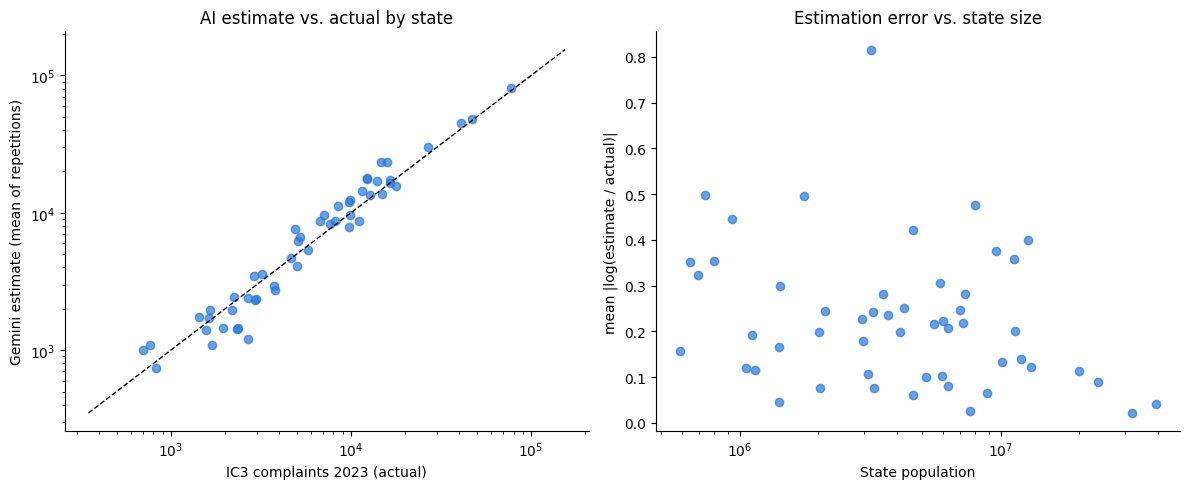

152 responses, 52 states


In [11]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

pop = pd.read_csv('ACSDT1Y2025.B01003-2026-11-10T204727.csv')
ic3 = pd.read_csv('ic3_complaints_by_state_v2.csv')
est = pop.iloc[0, 1:]
est = est[[c for c in est.index if c.endswith('!!Estimate')]]
pop_df = pd.DataFrame({'state': [c.replace('!!Estimate', '') for c in est.index],
                       'population': est.astype(str).str.replace(',', '').astype(int).values})
t = ic3.merge(pop_df, on='state')

pr = pd.read_csv('probe_2023_estimates.csv')
pr['estimate'] = pd.to_numeric(pr['estimate'], errors='coerce')
r = pr.merge(t[['state', 'complaints_2023', 'population']], on='state')
r['abs_log_err'] = np.log(r['estimate'] / r['complaints_2023']).abs()
g = r.dropna(subset=['estimate']).groupby('state').agg(est_mean=('estimate', 'mean'), abs_log_err=('abs_log_err', 'mean')).reset_index()
g = g.merge(t[['state', 'complaints_2023', 'population']], on='state')

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(g['complaints_2023'], g['est_mean'], alpha=0.7, color='#2a78d6')
lims = [g['complaints_2023'].min() * 0.5, g['complaints_2023'].max() * 2]
ax[0].plot(lims, lims, 'k--', lw=1); ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('IC3 complaints 2023 (actual)'); ax[0].set_ylabel('Gemini estimate (mean of repetitions)')
ax[0].set_title('AI estimate vs. actual by state')
ax[1].scatter(g['population'], g['abs_log_err'], alpha=0.7, color='#2a78d6')
ax[1].set_xscale('log'); ax[1].set_xlabel('State population'); ax[1].set_ylabel('mean |log(estimate / actual)|')
ax[1].set_title('Estimation error vs. state size')
for a in ax: a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('fig2_ai_probe_2023.png', dpi=200); plt.show()
print(len(r), "responses,", g['state'].nunique(), "states")

In [13]:
from google.colab import files
import os
for f in ["fig2_ai_probe_2023.png", "fig3_umd_unknown_state.png", "fig4_rq3_p1.png"]:
    if os.path.exists(f):
        files.download(f)
    else:
        print("এই ফাইল নেই:", f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

এই ফাইল নেই: fig3_umd_unknown_state.png
এই ফাইল নেই: fig4_rq3_p1.png


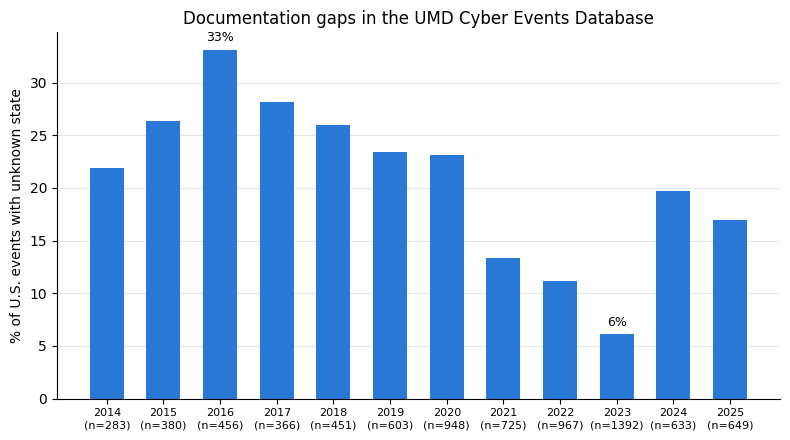

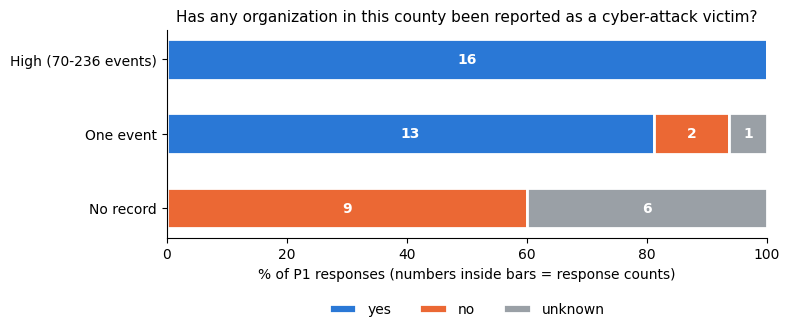

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from google.colab import files

umd = pd.read_csv('cyber_events_2026-11-10.csv', low_memory=False)

# ---- Figure 3: UMD-তে স্টেট অজানা ঘটনার শতাংশ ----
us = umd[umd['country'] == 'United States of America'].copy()
us['unknown_state'] = us['state'].isna() | (us['state'] == 'Undetermined')
g = us[us['year'].between(2014, 2025)].groupby('year')['unknown_state'].agg(['mean', 'size']).reset_index()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(g['year'], g['mean'] * 100, color='#2a78d6', width=0.6)
ax.set_xticks(g['year'])
ax.set_xticklabels([f"{y}\n(n={n})" for y, n in zip(g['year'], g['size'])], fontsize=8)
for idx in [g['mean'].idxmax(), g['mean'].idxmin()]:
    ax.text(g.loc[idx, 'year'], g.loc[idx, 'mean'] * 100 + 0.8, f"{g.loc[idx, 'mean']*100:.0f}%", ha='center', fontsize=9)
ax.set_ylabel('% of U.S. events with unknown state')
ax.set_title('Documentation gaps in the UMD Cyber Events Database')
ax.spines[['top', 'right']].set_visible(False)
ax.yaxis.grid(True, color='#e5e5e5'); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig('fig3_umd_unknown_state.png', dpi=200); plt.show()

# ---- Figure 4: RQ3, P1 উত্তরের ভাগ ----
r = pd.read_csv('probe_rq3.csv')
p1 = r[r['probe'] == 'P1']
order = ['S1_high', 'S2_one_event', 'S3_zero_events']
labels = ['High (70-236 events)', 'One event', 'No record']
cols = {'yes': '#2a78d6', 'no': '#eb6834', 'unknown': '#9aa0a6'}
ct = pd.crosstab(p1['stratum'], p1['answer']).reindex(order).reindex(columns=['yes', 'no', 'unknown']).fillna(0)

fig, ax = plt.subplots(figsize=(8, 3.6))
left = np.zeros(len(order))
for a in ['yes', 'no', 'unknown']:
    share = (ct[a] / ct.sum(axis=1)).values * 100
    ax.barh(labels, share, left=left, color=cols[a], edgecolor='white', linewidth=2, height=0.55, label=a)
    for i, (l, s_) in enumerate(zip(left, share)):
        if s_ > 6:
            ax.text(l + s_ / 2, i, f"{int(ct[a].iloc[i])}", ha='center', va='center', color='white', fontsize=10, fontweight='bold')
    left += share
ax.invert_yaxis()
ax.set_xlim(0, 100); ax.set_xlabel('% of P1 responses (numbers inside bars = response counts)')
ax.set_title('Has any organization in this county been reported as a cyber-attack victim?', fontsize=11)
ax.legend(ncol=3, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.25))
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('fig4_rq3_p1.png', dpi=200, bbox_inches='tight'); plt.show()

# ---- তিনটা ছবি ডাউনলোড ----
for f in ["fig2_ai_probe_2023.png", "fig3_umd_unknown_state.png", "fig4_rq3_p1.png"]:
    files.download(f)

In [15]:
# Makes all four figures at IEEE column sizes. Run in Colab after the files are uploaded.
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#9aa0a6'
plt.rcParams.update({'font.size': 7, 'axes.titlesize': 7.5, 'axes.labelsize': 7,
                     'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5, 'legend.fontsize': 6.5,
                     'axes.spines.top': False, 'axes.spines.right': False})
OUT = {'fig1': 'fig1_broadband_vs_complaints.png', 'fig2': 'fig2_umd_unknown_state.png',
       'fig3': 'fig3_ai_probe_2023.png', 'fig4': 'fig4_rq3_p1.png'}

# ---------- shared data ----------
umd = pd.read_csv('cyber_events_2026-11-10.csv', low_memory=False)
ic3 = pd.read_csv('ic3_complaints_by_state_v2.csv')
pop = pd.read_csv('ACSDT1Y2025.B01003-2026-11-10T204727.csv')
net = pd.read_csv('ACSST1Y2025.S2801-2026-11-10T204620.csv')
est = pop.iloc[0, 1:]
est = est[[c for c in est.index if c.endswith('!!Estimate')]]
pop_df = pd.DataFrame({'state': [c.replace('!!Estimate', '') for c in est.index],
                       'population': est.astype(str).str.replace(',', '').astype(int).values})
t = ic3.merge(pop_df, on='state', how='inner')
t['per100k_2025'] = (t['complaints_2025'] / t['population'] * 100000).round(1)

# ---------- Figure 1: broadband vs complaints ----------
net['label'] = net.iloc[:, 0].str.replace('\xa0', '', regex=False).str.strip()
row = net[net['label'] == 'Broadband of any type'].iloc[0]
cols = [c for c in net.columns if c.endswith('Percent!!Estimate')]
bb = pd.DataFrame({'state': [c.split('!!')[0] for c in cols],
                   'broadband_pct': [float(str(row[c]).replace('%', '')) for c in cols]})
t2 = t.merge(bb, on='state')
fig, ax = plt.subplots(figsize=(3.4, 2.6))
ax.scatter(t2['broadband_pct'], t2['per100k_2025'], s=9, alpha=0.8, color=BLUE, linewidths=0)
for _, r in t2.iterrows():
    if r['per100k_2025'] > 370 or r['per100k_2025'] < 150:
        ax.annotate(r['state'], (r['broadband_pct'], r['per100k_2025']), fontsize=5.5,
                    xytext=(2, 2), textcoords='offset points')
ax.set_xlabel('Households with broadband (%), ACS 2025')
ax.set_ylabel('IC3 complaints per 100,000, 2025')
ax.yaxis.grid(True, color='#e5e5e5', lw=0.5); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig(OUT['fig1'], dpi=300); plt.close()

# ---------- Figure 2: UMD unknown state ----------
us = umd[umd['country'] == 'United States of America'].copy()
us['unknown_state'] = us['state'].isna() | (us['state'] == 'Undetermined')
g = us[us['year'].between(2014, 2025)].groupby('year')['unknown_state'].agg(['mean', 'size']).reset_index()
fig, ax = plt.subplots(figsize=(3.4, 2.4))
ax.bar(g['year'], g['mean'] * 100, color=BLUE, width=0.65)
ax.set_xticks(g['year']); ax.set_xticklabels([str(y)[2:] for y in g['year']])
for idx in [g['mean'].idxmax(), g['mean'].idxmin()]:
    ax.text(g.loc[idx, 'year'], g.loc[idx, 'mean'] * 100 + 0.8, f"{g.loc[idx, 'mean']*100:.0f}%",
            ha='center', fontsize=6.5)
ax.set_xlabel("Year (20xx)"); ax.set_ylabel('% of U.S. events, state unknown')
ax.yaxis.grid(True, color='#e5e5e5', lw=0.5); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig(OUT['fig2'], dpi=300); plt.close()

# ---------- Figure 3: AI estimates (two panels, full width) ----------
pr = pd.read_csv('probe_2023_estimates.csv')
pr['estimate'] = pd.to_numeric(pr['estimate'], errors='coerce')
r = pr.merge(t[['state', 'complaints_2023', 'population']], on='state')
r['abs_log_err'] = np.log(r['estimate'] / r['complaints_2023']).abs()
gg = r.dropna(subset=['estimate']).groupby('state').agg(est_mean=('estimate', 'mean'),
        abs_log_err=('abs_log_err', 'mean')).reset_index().merge(t[['state', 'complaints_2023', 'population']], on='state')
fig, ax = plt.subplots(1, 2, figsize=(7.0, 2.6))
ax[0].scatter(gg['complaints_2023'], gg['est_mean'], s=9, alpha=0.8, color=BLUE, linewidths=0)
lims = [gg['complaints_2023'].min() * 0.6, gg['complaints_2023'].max() * 1.6]
ax[0].plot(lims, lims, color='black', ls='--', lw=0.7); ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('IC3 complaints 2023 (actual)'); ax[0].set_ylabel('Model estimate (mean of 3 runs)')
ax[0].set_title('(a) Estimate vs. actual, by state')
ax[1].scatter(gg['population'], gg['abs_log_err'], s=9, alpha=0.8, color=BLUE, linewidths=0)
ax[1].set_xscale('log'); ax[1].set_xlabel('State population'); ax[1].set_ylabel('Mean |log(estimate / actual)|')
ax[1].set_title('(b) Error vs. state size')
plt.tight_layout(); plt.savefig(OUT['fig3'], dpi=300); plt.close()

# ---------- Figure 4: RQ3, P1 answers ----------
rq = pd.read_csv('probe_rq3.csv'); p1 = rq[rq['probe'] == 'P1']
order = ['S1_high', 'S2_one_event', 'S3_zero_events']
labels = ['High\n(70-236 events)', 'One event', 'No record']
cols4 = {'yes': BLUE, 'no': ORANGE, 'unknown': GREY}
ct = pd.crosstab(p1['stratum'], p1['answer']).reindex(order).reindex(columns=['yes', 'no', 'unknown']).fillna(0)
fig, ax = plt.subplots(figsize=(3.4, 2.0))
left = np.zeros(len(order))
for a in ['yes', 'no', 'unknown']:
    share = (ct[a] / ct.sum(axis=1)).values * 100
    ax.barh(labels, share, left=left, color=cols4[a], edgecolor='white', linewidth=1.5, height=0.55, label=a)
    for i, (l, s_) in enumerate(zip(left, share)):
        if s_ > 6:
            ax.text(l + s_ / 2, i, f"{int(ct[a].iloc[i])}", ha='center', va='center', color='white',
                    fontsize=7, fontweight='bold')
    left += share
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel('% of P1 responses (numbers = response counts)')
ax.legend(ncol=3, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.32))
plt.tight_layout(); plt.savefig(OUT['fig4'], dpi=300, bbox_inches='tight'); plt.close()
print('done:', list(OUT.values()))

# ---------- download the four figures ----------
from google.colab import files
for f in OUT.values():
    files.download(f)

done: ['fig1_broadband_vs_complaints.png', 'fig2_umd_unknown_state.png', 'fig3_ai_probe_2023.png', 'fig4_rq3_p1.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
# Makes all four figures at IEEE column sizes. Run in Colab after the files are uploaded.
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#9aa0a6'
plt.rcParams.update({'font.size': 7, 'axes.titlesize': 7.5, 'axes.labelsize': 7,
                     'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5, 'legend.fontsize': 6.5,
                     'axes.spines.top': False, 'axes.spines.right': False})
OUT = {'map': 'fig1_map_ic3_vs_umd.png', 'fig1': 'fig2_broadband_vs_complaints.png',
       'fig2': 'fig3_umd_unknown_state.png', 'fig3': 'fig4_ai_probe_2023.png', 'fig4': 'fig5_rq3_p1.png'}

# ---------- shared data ----------
umd = pd.read_csv('cyber_events_2026-11-10.csv', low_memory=False)
ic3 = pd.read_csv('ic3_complaints_by_state_v2.csv')
pop = pd.read_csv('ACSDT1Y2025.B01003-2026-11-10T204727.csv')
net = pd.read_csv('ACSST1Y2025.S2801-2026-11-10T204620.csv')
est = pop.iloc[0, 1:]
est = est[[c for c in est.index if c.endswith('!!Estimate')]]
pop_df = pd.DataFrame({'state': [c.replace('!!Estimate', '') for c in est.index],
                       'population': est.astype(str).str.replace(',', '').astype(int).values})
t = ic3.merge(pop_df, on='state', how='inner')
t['per100k_2025'] = (t['complaints_2025'] / t['population'] * 100000).round(1)

# ---------- Figure 1: tile-grid maps, IC3 vs UMD ----------
from matplotlib.colors import Normalize
ab = {'Alabama':'AL','Alaska':'AK','Arizona':'AZ','Arkansas':'AR','California':'CA','Colorado':'CO','Connecticut':'CT','Delaware':'DE','District of Columbia':'DC','Florida':'FL','Georgia':'GA','Hawaii':'HI','Idaho':'ID','Illinois':'IL','Indiana':'IN','Iowa':'IA','Kansas':'KS','Kentucky':'KY','Louisiana':'LA','Maine':'ME','Maryland':'MD','Massachusetts':'MA','Michigan':'MI','Minnesota':'MN','Mississippi':'MS','Missouri':'MO','Montana':'MT','Nebraska':'NE','Nevada':'NV','New Hampshire':'NH','New Jersey':'NJ','New Mexico':'NM','New York':'NY','North Carolina':'NC','North Dakota':'ND','Ohio':'OH','Oklahoma':'OK','Oregon':'OR','Pennsylvania':'PA','Rhode Island':'RI','South Carolina':'SC','South Dakota':'SD','Tennessee':'TN','Texas':'TX','Utah':'UT','Vermont':'VT','Virginia':'VA','Washington':'WA','West Virginia':'WV','Wisconsin':'WI','Wyoming':'WY','Puerto Rico':'PR'}
grid = {'AK':(0,0),'ME':(0,10),'VT':(1,9),'NH':(1,10),
 'WA':(2,0),'ID':(2,1),'MT':(2,2),'ND':(2,3),'MN':(2,4),'IL':(2,5),'WI':(2,6),'MI':(2,7),'NY':(2,8),'RI':(2,9),'MA':(2,10),
 'OR':(3,0),'NV':(3,1),'WY':(3,2),'SD':(3,3),'IA':(3,4),'IN':(3,5),'OH':(3,6),'PA':(3,7),'NJ':(3,8),'CT':(3,9),
 'CA':(4,0),'UT':(4,1),'CO':(4,2),'NE':(4,3),'MO':(4,4),'KY':(4,5),'WV':(4,6),'VA':(4,7),'MD':(4,8),'DE':(4,9),
 'AZ':(5,1),'NM':(5,2),'KS':(5,3),'AR':(5,4),'TN':(5,5),'NC':(5,6),'SC':(5,7),'DC':(5,8),
 'OK':(6,3),'LA':(6,4),'MS':(6,5),'AL':(6,6),'GA':(6,7),
 'HI':(7,0),'TX':(7,3),'FL':(7,8),'PR':(7,10)}
us_ = umd[umd['country'] == 'United States of America']
rec = us_[us_['year'].between(2023, 2025) & us_['state'].notna() & (us_['state'] != 'Undetermined')]
cnt = rec['state'].value_counts().rename_axis('state').reset_index(name='umd_events')
m = t.merge(cnt, on='state', how='left').fillna({'umd_events': 0})
m['ic3'] = m['complaints_2025'] / m['population'] * 1e5
m['umd'] = m['umd_events'] / m['population'] * 1e6
m['abbr'] = m['state'].map(ab)
def tiles(ax, col, title, label):
    vals = m.set_index('abbr')[col]
    norm = Normalize(vmin=vals.min(), vmax=vals.max()); cmap = plt.cm.Blues
    for a,(r,c) in grid.items():
        v = vals[a]; rgba = cmap(0.12+0.83*norm(v))
        ax.add_patch(plt.Rectangle((c,-r),0.92,0.92,color=rgba,lw=0))
        lum = 0.299*rgba[0]+0.587*rgba[1]+0.114*rgba[2]
        ax.text(c+0.46,-r+0.46,a,ha='center',va='center',fontsize=5.5,color='white' if lum<0.55 else '#222')
    ax.set_xlim(-0.1,11); ax.set_ylim(-7.1,1); ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(title,fontsize=7.5)
    sm = plt.cm.ScalarMappable(norm=Normalize(vals.min(),vals.max()),cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list('b',[cmap(0.12),cmap(0.95)]))
    cb = plt.colorbar(sm,ax=ax,orientation='horizontal',fraction=0.05,pad=0.02,aspect=30); cb.ax.tick_params(labelsize=6); cb.set_label(label,fontsize=6.5); cb.outline.set_linewidth(0)
fig, axs = plt.subplots(1, 2, figsize=(7.0, 3.2))
tiles(axs[0], 'ic3', '(a) IC3 complaints, 2025', 'complaints per 100,000 residents')
tiles(axs[1], 'umd', '(b) UMD events, 2023-2025', 'events per million residents')
fig.subplots_adjust(top=0.92, bottom=0.17, left=0.01, right=0.99, wspace=0.05)
plt.savefig(OUT['map'], dpi=300); plt.close()

# ---------- Figure 2: broadband vs complaints ----------
net['label'] = net.iloc[:, 0].str.replace('\xa0', '', regex=False).str.strip()
row = net[net['label'] == 'Broadband of any type'].iloc[0]
cols = [c for c in net.columns if c.endswith('Percent!!Estimate')]
bb = pd.DataFrame({'state': [c.split('!!')[0] for c in cols],
                   'broadband_pct': [float(str(row[c]).replace('%', '')) for c in cols]})
t2 = t.merge(bb, on='state')
fig, ax = plt.subplots(figsize=(3.4, 2.6))
ax.scatter(t2['broadband_pct'], t2['per100k_2025'], s=9, alpha=0.8, color=BLUE, linewidths=0)
for _, r in t2.iterrows():
    if r['per100k_2025'] > 370 or r['per100k_2025'] < 150:
        ax.annotate(r['state'], (r['broadband_pct'], r['per100k_2025']), fontsize=5.5,
                    xytext=(2, 2), textcoords='offset points')
ax.set_xlabel('Households with broadband (%), ACS 2025')
ax.set_ylabel('IC3 complaints per 100,000, 2025')
ax.yaxis.grid(True, color='#e5e5e5', lw=0.5); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig(OUT['fig1'], dpi=300); plt.close()

# ---------- Figure 3: UMD unknown state ----------
us = umd[umd['country'] == 'United States of America'].copy()
us['unknown_state'] = us['state'].isna() | (us['state'] == 'Undetermined')
g = us[us['year'].between(2014, 2025)].groupby('year')['unknown_state'].agg(['mean', 'size']).reset_index()
fig, ax = plt.subplots(figsize=(3.4, 2.4))
ax.bar(g['year'], g['mean'] * 100, color=BLUE, width=0.65)
ax.set_xticks(g['year']); ax.set_xticklabels([str(y)[2:] for y in g['year']])
for idx in [g['mean'].idxmax(), g['mean'].idxmin()]:
    ax.text(g.loc[idx, 'year'], g.loc[idx, 'mean'] * 100 + 0.8, f"{g.loc[idx, 'mean']*100:.0f}%",
            ha='center', fontsize=6.5)
ax.set_xlabel("Year (20xx)"); ax.set_ylabel('% of U.S. events, state unknown')
ax.yaxis.grid(True, color='#e5e5e5', lw=0.5); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig(OUT['fig2'], dpi=300); plt.close()

# ---------- Figure 4: AI estimates (two panels, full width) ----------
pr = pd.read_csv('probe_2023_estimates.csv')
pr['estimate'] = pd.to_numeric(pr['estimate'], errors='coerce')
r = pr.merge(t[['state', 'complaints_2023', 'population']], on='state')
r['abs_log_err'] = np.log(r['estimate'] / r['complaints_2023']).abs()
gg = r.dropna(subset=['estimate']).groupby('state').agg(est_mean=('estimate', 'mean'),
        abs_log_err=('abs_log_err', 'mean')).reset_index().merge(t[['state', 'complaints_2023', 'population']], on='state')
fig, ax = plt.subplots(1, 2, figsize=(7.0, 2.6))
ax[0].scatter(gg['complaints_2023'], gg['est_mean'], s=9, alpha=0.8, color=BLUE, linewidths=0)
lims = [gg['complaints_2023'].min() * 0.6, gg['complaints_2023'].max() * 1.6]
ax[0].plot(lims, lims, color='black', ls='--', lw=0.7); ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('IC3 complaints 2023 (actual)'); ax[0].set_ylabel('Model estimate (mean of 3 runs)')
ax[0].set_title('(a) Estimate vs. actual, by state')
ax[1].scatter(gg['population'], gg['abs_log_err'], s=9, alpha=0.8, color=BLUE, linewidths=0)
ax[1].set_xscale('log'); ax[1].set_xlabel('State population'); ax[1].set_ylabel('Mean |log(estimate / actual)|')
ax[1].set_title('(b) Error vs. state size')
plt.tight_layout(); plt.savefig(OUT['fig3'], dpi=300); plt.close()

# ---------- Figure 5: RQ3, P1 answers ----------
rq = pd.read_csv('probe_rq3.csv'); p1 = rq[rq['probe'] == 'P1']
order = ['S1_high', 'S2_one_event', 'S3_zero_events']
labels = ['High\n(70-236 events)', 'One event', 'No record']
cols4 = {'yes': BLUE, 'no': ORANGE, 'unknown': GREY}
ct = pd.crosstab(p1['stratum'], p1['answer']).reindex(order).reindex(columns=['yes', 'no', 'unknown']).fillna(0)
fig, ax = plt.subplots(figsize=(3.4, 2.0))
left = np.zeros(len(order))
for a in ['yes', 'no', 'unknown']:
    share = (ct[a] / ct.sum(axis=1)).values * 100
    ax.barh(labels, share, left=left, color=cols4[a], edgecolor='white', linewidth=1.5, height=0.55, label=a)
    for i, (l, s_) in enumerate(zip(left, share)):
        if s_ > 6:
            ax.text(l + s_ / 2, i, f"{int(ct[a].iloc[i])}", ha='center', va='center', color='white',
                    fontsize=7, fontweight='bold')
    left += share
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel('% of P1 responses (numbers = response counts)')
ax.legend(ncol=3, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.32))
plt.tight_layout(); plt.savefig(OUT['fig4'], dpi=300, bbox_inches='tight'); plt.close()
print('done:', list(OUT.values()))

# ---------- download the four figures ----------
from google.colab import files
for f in OUT.values():
    files.download(f)

done: ['fig1_map_ic3_vs_umd.png', 'fig2_broadband_vs_complaints.png', 'fig3_umd_unknown_state.png', 'fig4_ai_probe_2023.png', 'fig5_rq3_p1.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
print(gg.sort_values('abs_log_err', ascending=False).head(3)[['state','abs_log_err','complaints_2023','est_mean']])

            state  abs_log_err  complaints_2023     est_mean
39    Puerto Rico     0.815877             2678  1201.000000
1          Alaska     0.497600             2338  1421.666667
49  West Virginia     0.496460             2365  1440.000000


In [20]:
# ===== CELL A: county populations (ACS 5-year) + size/documentation table =====
import os
import pandas as pd, numpy as np

def get_county_pop():
    # Census Population Estimates (vintage 2025): population of every county, including very small ones
    fname = "co-est2025-alldata.csv"
    url = "https://www2.census.gov/programs-surveys/popest/datasets/2020-2025/counties/totals/" + fname
    src = fname if os.path.exists(fname) else url
    try:
        df = pd.read_csv(src, encoding="latin-1")
    except Exception as e:
        raise SystemExit("Could not download the Census file (" + str(e)[:80] + "). Download it in your browser from\n"
                         + url + "\nupload it to Colab (left Files panel) and run this cell again.")
    df = df[df["SUMLEV"] == 50].copy()          # 50 = county rows (40 = state rows)
    popcol = sorted(c for c in df.columns if c.startswith("POPESTIMATE"))[-1]
    df = df.rename(columns={"STNAME": "state", "CTYNAME": "county_name", popcol: "population"})
    print(f"Census {popcol}: {len(df)} counties")
    return df[["state", "county_name", "population"]]

def key(state, county):
    c = (county.astype(str).str.replace(r" (County|Parish)$", "", regex=True)
         .str.strip().str.lower())
    return state.astype(str).str.strip() + "|" + c

cp = get_county_pop()
cp["key"] = key(cp["state"], cp["county_name"])

rq = pd.read_csv("probe_rq3.csv")
p1 = rq[rq["probe"] == "P1"].copy()
p1["key"] = key(p1["state"], p1["county"])
tab = (p1.groupby(["stratum", "state", "county", "key"])["answer"].value_counts()
         .unstack(fill_value=0).reset_index())
for a in ["yes", "no", "unknown"]:
    if a not in tab: tab[a] = 0
tab = tab.merge(cp[["key", "population"]], on="key", how="left")
print("\nCounties not matched to Census (check spelling):",
      tab.loc[tab["population"].isna(), ["state", "county"]].values.tolist())
tab = tab.sort_values("population")
print(tab[["stratum", "state", "county", "population", "yes", "no", "unknown"]].to_string(index=False))
tab.to_csv("rq3_county_population.csv", index=False)

Census POPESTIMATE2025: 3144 counties

Counties not matched to Census (check spelling): [['New Jersey', 'Hillsborough']]
       stratum          state       county  population  yes  no  unknown
S3_zero_events          Texas       Loving        52.0    0   2        0
S3_zero_events          Texas         King       192.0    0   0        1
S3_zero_events          Texas       Kenedy       319.0    0   2        0
S3_zero_events       Nebraska    McPherson       369.0    0   0        2
S3_zero_events       Nebraska       Arthur       396.0    0   0        2
S3_zero_events        Montana    Petroleum       548.0    0   2        0
S3_zero_events          Texas       Borden       567.0    0   2        0
S3_zero_events        Montana     Treasure       728.0    0   1        1
  S2_one_event        Alabama     Escambia     36665.0    2   0        0
  S2_one_event  West Virginia        Wayne     37309.0    1   1        0
  S2_one_event       New York      Wyoming     39741.0    0   1        1
  S

In [21]:
# ===== CELL B: new stratum - mid-size counties with NO UMD record, same P1 question =====
import os, time, json
import pandas as pd, numpy as np
try:
    client
except NameError:
    try:
        from google import genai
    except ImportError:
        import subprocess, sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "google-genai"])
        from google import genai
    from google.colab import userdata
    client = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))
from google.genai import types
MODEL = "gemini-3.1-flash-lite"
cfg = types.GenerateContentConfig(response_mime_type="application/json", temperature=0.7)

# same P1 wording as before
P1 = ("Between 2014 and 2025, has any organization located in {county} County, {state} been publicly reported "
      "as the victim of a cyber attack (for example ransomware or a data breach)? Respond ONLY as JSON: "
      '{{"answer": "yes" or "no" or "unknown", "confidence": <number 0 to 1>, "note": "<one short sentence>"}}')

umd = pd.read_csv("cyber_events_2026-11-10.csv", low_memory=False)
us = umd[(umd["country"] == "United States of America") & umd["county"].notna() & umd["state"].notna()]
umd_keys = set(key(us["state"], us["county"]))

cand = cp[cp["county_name"].str.endswith(" County") & cp["population"].between(25000, 60000)].copy()
cand = cand[~cand["key"].isin(umd_keys)]
print("mid-size counties (25k-60k) with no UMD record:", len(cand))
pick = cand.sample(8, random_state=42).copy()
pick["county"] = pick["county_name"].str.replace(" County", "", regex=False)
print(pick[["state", "county", "population"]].to_string(index=False))

def ask_prompt(prompt, tries=3):
    for k in range(tries):
        try:
            r = client.models.generate_content(model=MODEL, contents=prompt, config=cfg)
            return json.loads(r.text)
        except Exception as e:
            print("  retry", str(e)[:60]); time.sleep(30 * (k + 1))
    return None

OUT, REPS, PAUSE = "probe_rq3_size.csv", 2, 10
rows = pd.read_csv(OUT).to_dict("records") if os.path.exists(OUT) else []
done = {(r["state"], r["county"], r["rep"]) for r in rows}
fails, stop = 0, False
for rep in range(REPS):
    for _, p in pick.iterrows():
        if (p.state, p.county, rep) in done: continue
        out = ask_prompt(P1.format(state=p.state, county=p.county))
        if out is None:
            fails += 1
            if fails >= 3: stop = True; break
            continue
        fails = 0
        out.update(stratum="S4_zero_midsize", state=p.state, county=p.county,
                   population=int(p.population), probe="P1", rep=rep)
        rows.append(out); pd.DataFrame(rows).to_csv(OUT, index=False); time.sleep(PAUSE)
    if stop: print("STOPPED: 3 failures in a row. Saved so far:", len(rows)); break
    print("round", rep, "finished | total saved:", len(rows))
print("DONE" if not stop else "PARTIAL", len(rows), "responses")

mid-size counties (25k-60k) with no UMD record: 461
      state    county  population
    Montana   Ravalli       48582
    Florida    DeSoto       37078
    Georgia Chattooga       25300
   Missouri    Warren       39016
   Kentucky      Boyd       47751
Mississippi     Scott       28073
      Texas      Rusk       54854
   Missouri   Johnson       56670
round 0 finished | total saved: 8
round 1 finished | total saved: 16
DONE 16 responses


In [22]:
# ===== CELL C: compare same-size counties: 1 UMD event vs 0 UMD events =====
new = pd.read_csv("probe_rq3_size.csv")
rows_old = p1.merge(cp[["key", "population"]], on="key", how="left")
same = rows_old[(rows_old["stratum"] == "S2_one_event") & rows_old["population"].between(25000, 60000)]
grp = pd.concat([same[["stratum", "county", "population", "answer"]],
                 new[["stratum", "county", "population", "answer"]]])
print("Counties compared (population 25k-60k):")
print(grp.groupby(["stratum", "county"])["population"].first().to_string())
print("\nP1 answers, share of responses:")
print(pd.crosstab(grp["stratum"], grp["answer"], normalize="index").round(2).to_string())
print("\nP1 answers, counts:")
print(pd.crosstab(grp["stratum"], grp["answer"]).to_string())
if "confidence" in new:
    print("\nmean confidence (new stratum):", round(pd.to_numeric(new["confidence"], errors="coerce").mean(), 2))

Counties compared (population 25k-60k):
stratum          county    
S2_one_event     Escambia      36665.0
                 Sweetwater    41267.0
                 Wayne         37309.0
                 Wyoming       39741.0
S4_zero_midsize  Boyd          47751.0
                 Chattooga     25300.0
                 DeSoto        37078.0
                 Johnson       56670.0
                 Ravalli       48582.0
                 Rusk          54854.0
                 Scott         28073.0
                 Warren        39016.0

P1 answers, share of responses:
answer             no  unknown   yes
stratum                             
S2_one_event     0.25     0.12  0.62
S4_zero_midsize  0.25     0.12  0.62

P1 answers, counts:
answer           no  unknown  yes
stratum                          
S2_one_event      2        1    5
S4_zero_midsize   4        2   10

mean confidence (new stratum): 0.79


In [24]:
# Makes all four figures at IEEE column sizes. Run in Colab after the files are uploaded.
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#9aa0a6'
plt.rcParams.update({'font.size': 7, 'axes.titlesize': 7.5, 'axes.labelsize': 7,
                     'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5, 'legend.fontsize': 6.5,
                     'axes.spines.top': False, 'axes.spines.right': False})
OUT = {'map': 'fig1_map_ic3_vs_umd.png', 'fig1': 'fig2_broadband_vs_complaints.png',
       'fig2': 'fig3_umd_unknown_state.png', 'fig3': 'fig4_ai_probe_2023.png', 'fig4': 'fig5_rq3_p1.png'}

# ---------- shared data ----------
umd = pd.read_csv('cyber_events_2026-11-10.csv', low_memory=False)
ic3 = pd.read_csv('ic3_complaints_by_state_v2.csv')
pop = pd.read_csv('ACSDT1Y2025.B01003-2026-11-10T204727.csv')
net = pd.read_csv('ACSST1Y2025.S2801-2026-11-10T204620.csv')
est = pop.iloc[0, 1:]
est = est[[c for c in est.index if c.endswith('!!Estimate')]]
pop_df = pd.DataFrame({'state': [c.replace('!!Estimate', '') for c in est.index],
                       'population': est.astype(str).str.replace(',', '').astype(int).values})
t = ic3.merge(pop_df, on='state', how='inner')
t['per100k_2025'] = (t['complaints_2025'] / t['population'] * 100000).round(1)

# ---------- Figure 1: tile-grid maps, IC3 vs UMD ----------
from matplotlib.colors import Normalize
ab = {'Alabama':'AL','Alaska':'AK','Arizona':'AZ','Arkansas':'AR','California':'CA','Colorado':'CO','Connecticut':'CT','Delaware':'DE','District of Columbia':'DC','Florida':'FL','Georgia':'GA','Hawaii':'HI','Idaho':'ID','Illinois':'IL','Indiana':'IN','Iowa':'IA','Kansas':'KS','Kentucky':'KY','Louisiana':'LA','Maine':'ME','Maryland':'MD','Massachusetts':'MA','Michigan':'MI','Minnesota':'MN','Mississippi':'MS','Missouri':'MO','Montana':'MT','Nebraska':'NE','Nevada':'NV','New Hampshire':'NH','New Jersey':'NJ','New Mexico':'NM','New York':'NY','North Carolina':'NC','North Dakota':'ND','Ohio':'OH','Oklahoma':'OK','Oregon':'OR','Pennsylvania':'PA','Rhode Island':'RI','South Carolina':'SC','South Dakota':'SD','Tennessee':'TN','Texas':'TX','Utah':'UT','Vermont':'VT','Virginia':'VA','Washington':'WA','West Virginia':'WV','Wisconsin':'WI','Wyoming':'WY','Puerto Rico':'PR'}
grid = {'AK':(0,0),'ME':(0,10),'VT':(1,9),'NH':(1,10),
 'WA':(2,0),'ID':(2,1),'MT':(2,2),'ND':(2,3),'MN':(2,4),'IL':(2,5),'WI':(2,6),'MI':(2,7),'NY':(2,8),'RI':(2,9),'MA':(2,10),
 'OR':(3,0),'NV':(3,1),'WY':(3,2),'SD':(3,3),'IA':(3,4),'IN':(3,5),'OH':(3,6),'PA':(3,7),'NJ':(3,8),'CT':(3,9),
 'CA':(4,0),'UT':(4,1),'CO':(4,2),'NE':(4,3),'MO':(4,4),'KY':(4,5),'WV':(4,6),'VA':(4,7),'MD':(4,8),'DE':(4,9),
 'AZ':(5,1),'NM':(5,2),'KS':(5,3),'AR':(5,4),'TN':(5,5),'NC':(5,6),'SC':(5,7),'DC':(5,8),
 'OK':(6,3),'LA':(6,4),'MS':(6,5),'AL':(6,6),'GA':(6,7),
 'HI':(7,0),'TX':(7,3),'FL':(7,8),'PR':(7,10)}
us_ = umd[umd['country'] == 'United States of America']
rec = us_[us_['year'].between(2023, 2025) & us_['state'].notna() & (us_['state'] != 'Undetermined')]
cnt = rec['state'].value_counts().rename_axis('state').reset_index(name='umd_events')
m = t.merge(cnt, on='state', how='left').fillna({'umd_events': 0})
m['ic3'] = m['complaints_2025'] / m['population'] * 1e5
m['umd'] = m['umd_events'] / m['population'] * 1e6
m['abbr'] = m['state'].map(ab)
def tiles(ax, col, title, label):
    vals = m.set_index('abbr')[col]
    norm = Normalize(vmin=vals.min(), vmax=vals.max()); cmap = plt.cm.Blues
    for a,(r,c) in grid.items():
        v = vals[a]; rgba = cmap(0.12+0.83*norm(v))
        ax.add_patch(plt.Rectangle((c,-r),0.92,0.92,color=rgba,lw=0))
        lum = 0.299*rgba[0]+0.587*rgba[1]+0.114*rgba[2]
        ax.text(c+0.46,-r+0.46,a,ha='center',va='center',fontsize=5.5,color='white' if lum<0.55 else '#222')
    ax.set_xlim(-0.1,11); ax.set_ylim(-7.1,1); ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(title,fontsize=7.5)
    sm = plt.cm.ScalarMappable(norm=Normalize(vals.min(),vals.max()),cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list('b',[cmap(0.12),cmap(0.95)]))
    cb = plt.colorbar(sm,ax=ax,orientation='horizontal',fraction=0.05,pad=0.02,aspect=30); cb.ax.tick_params(labelsize=6); cb.set_label(label,fontsize=6.5); cb.outline.set_linewidth(0)
fig, axs = plt.subplots(1, 2, figsize=(7.0, 3.2))
tiles(axs[0], 'ic3', '(a) IC3 complaints, 2025', 'complaints per 100,000 residents')
tiles(axs[1], 'umd', '(b) UMD events, 2023-2025', 'events per million residents')
fig.subplots_adjust(top=0.92, bottom=0.17, left=0.01, right=0.99, wspace=0.05)
plt.savefig(OUT['map'], dpi=300); plt.close()

# ---------- Figure 2: broadband vs complaints ----------
net['label'] = net.iloc[:, 0].str.replace('\xa0', '', regex=False).str.strip()
row = net[net['label'] == 'Broadband of any type'].iloc[0]
cols = [c for c in net.columns if c.endswith('Percent!!Estimate')]
bb = pd.DataFrame({'state': [c.split('!!')[0] for c in cols],
                   'broadband_pct': [float(str(row[c]).replace('%', '')) for c in cols]})
t2 = t.merge(bb, on='state')
fig, ax = plt.subplots(figsize=(3.4, 2.6))
ax.scatter(t2['broadband_pct'], t2['per100k_2025'], s=9, alpha=0.8, color=BLUE, linewidths=0)
for _, r in t2.iterrows():
    if r['per100k_2025'] > 370 or r['per100k_2025'] < 150:
        ax.annotate(r['state'], (r['broadband_pct'], r['per100k_2025']), fontsize=5.5,
                    xytext=(2, 2), textcoords='offset points')
ax.set_xlabel('Households with broadband (%), ACS 2025')
ax.set_ylabel('IC3 complaints per 100,000, 2025')
ax.yaxis.grid(True, color='#e5e5e5', lw=0.5); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig(OUT['fig1'], dpi=300); plt.close()

# ---------- Figure 3: UMD unknown state ----------
us = umd[umd['country'] == 'United States of America'].copy()
us['unknown_state'] = us['state'].isna() | (us['state'] == 'Undetermined')
g = us[us['year'].between(2014, 2025)].groupby('year')['unknown_state'].agg(['mean', 'size']).reset_index()
fig, ax = plt.subplots(figsize=(3.4, 2.4))
ax.bar(g['year'], g['mean'] * 100, color=BLUE, width=0.65)
ax.set_xticks(g['year']); ax.set_xticklabels([str(y)[2:] for y in g['year']])
for idx in [g['mean'].idxmax(), g['mean'].idxmin()]:
    ax.text(g.loc[idx, 'year'], g.loc[idx, 'mean'] * 100 + 0.8, f"{g.loc[idx, 'mean']*100:.0f}%",
            ha='center', fontsize=6.5)
ax.set_xlabel("Year (20xx)"); ax.set_ylabel('% of U.S. events, state unknown')
ax.yaxis.grid(True, color='#e5e5e5', lw=0.5); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig(OUT['fig2'], dpi=300); plt.close()

# ---------- Figure 4: AI estimates (two panels, full width) ----------
pr = pd.read_csv('probe_2023_estimates.csv')
pr['estimate'] = pd.to_numeric(pr['estimate'], errors='coerce')
r = pr.merge(t[['state', 'complaints_2023', 'population']], on='state')
r['abs_log_err'] = np.log(r['estimate'] / r['complaints_2023']).abs()
gg = r.dropna(subset=['estimate']).groupby('state').agg(est_mean=('estimate', 'mean'),
        abs_log_err=('abs_log_err', 'mean')).reset_index().merge(t[['state', 'complaints_2023', 'population']], on='state')
fig, ax = plt.subplots(1, 2, figsize=(7.0, 2.6))
ax[0].scatter(gg['complaints_2023'], gg['est_mean'], s=9, alpha=0.8, color=BLUE, linewidths=0)
lims = [gg['complaints_2023'].min() * 0.6, gg['complaints_2023'].max() * 1.6]
ax[0].plot(lims, lims, color='black', ls='--', lw=0.7); ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('IC3 complaints 2023 (actual)'); ax[0].set_ylabel('Model estimate (mean of 3 runs)')
ax[0].set_title('(a) Estimate vs. actual, by state')
ax[1].scatter(gg['population'], gg['abs_log_err'], s=9, alpha=0.8, color=BLUE, linewidths=0)
ax[1].set_xscale('log'); ax[1].set_xlabel('State population'); ax[1].set_ylabel('Mean |log(estimate / actual)|')
ax[1].set_title('(b) Error vs. state size')
plt.tight_layout(); plt.savefig(OUT['fig3'], dpi=300); plt.close()

# ---------- Figure 5: RQ3, P1 answers (4 strata) ----------
rq = pd.concat([pd.read_csv('probe_rq3.csv'), pd.read_csv('probe_rq3_size.csv')], ignore_index=True)
p1 = rq[rq['probe'] == 'P1']
order = ['S1_high', 'S2_one_event', 'S3_zero_events', 'S4_zero_midsize']
labels = ['High\n(70-236 events)', 'One event', 'No record,\ntiny (<1,000)', 'No record,\nmid-size (25-60k)']
cols4 = {'yes': BLUE, 'no': ORANGE, 'unknown': GREY}
ct = pd.crosstab(p1['stratum'], p1['answer']).reindex(order).reindex(columns=['yes', 'no', 'unknown']).fillna(0)
fig, ax = plt.subplots(figsize=(3.4, 2.5))
left = np.zeros(len(order))
for a in ['yes', 'no', 'unknown']:
    share = (ct[a] / ct.sum(axis=1)).values * 100
    ax.barh(labels, share, left=left, color=cols4[a], edgecolor='white', linewidth=1.5, height=0.6, label=a)
    for i, (l, s_) in enumerate(zip(left, share)):
        if s_ > 6:
            ax.text(l + s_ / 2, i, f"{int(ct[a].iloc[i])}", ha='center', va='center', color='white',
                    fontsize=7, fontweight='bold')
    left += share
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel('% of P1 responses (numbers = response counts)')
ax.legend(ncol=3, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.28))
plt.tight_layout(); plt.savefig(OUT['fig4'], dpi=300, bbox_inches='tight'); plt.close()
print('done:', list(OUT.values()))

# ---------- download the four figures ----------
from google.colab import files
for f in OUT.values():
    files.download(f)

done: ['fig1_map_ic3_vs_umd.png', 'fig2_broadband_vs_complaints.png', 'fig3_umd_unknown_state.png', 'fig4_ai_probe_2023.png', 'fig5_rq3_p1.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
import shutil, os
from google.colab import files

keep = [
 'ic3_complaints_by_state_v2.csv',
 'probe_2023_estimates.csv', 'probe_rq3.csv', 'probe_rq3_size.csv',
 'rq3_county_population.csv',
 'ACSDT1Y2025.B01003-2026-11-10T204727.csv',
 'ACSST1Y2025.S2801-2026-11-10T204620.csv',
 'fig1_map_ic3_vs_umd.png', 'fig2_broadband_vs_complaints.png',
 'fig3_umd_unknown_state.png', 'fig4_ai_probe_2023.png',
 'fig5_rq3_p1.png',
]
shutil.rmtree('repo', ignore_errors=True)
os.makedirs('repo/data'); os.makedirs('repo/figures')
for f in keep:
    if os.path.exists(f):
        shutil.copy(f, 'repo/figures' if f.endswith('.png') else 'repo/data')
    else:
        print('MISSING:', f)
shutil.make_archive('repo', 'zip', 'repo')
files.download('repo.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>